In [1]:
#library
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2

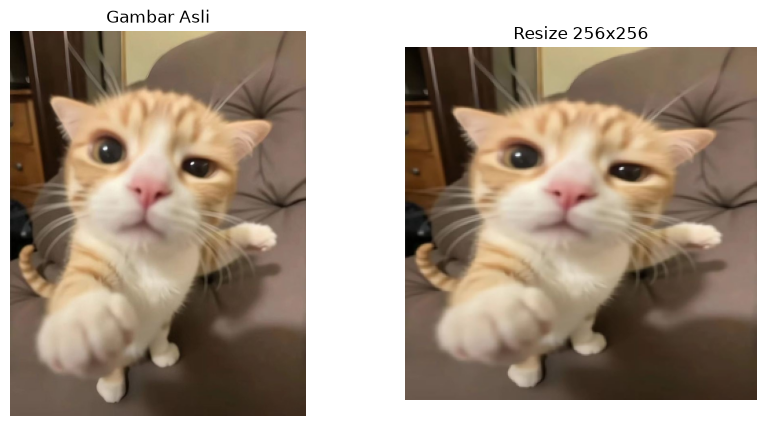

In [2]:
from pathlib import Path
#soal 1
#laod gambar
img_path = str(Path.cwd().parent / "data" / "sample_image.jpeg")
img = Image.open(img_path).convert('RGB')
img_resized = img.resize((256, 256))
img_np = np.array(img_resized, dtype=np.float32)

#gambar asli dan resize
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Gambar Asli")
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(img_resized)
plt.title("Resize 256x256")
plt.axis('off')
plt.show()


In [3]:
#soal 2
#ubah menjadi array
img_np = np.array(img_resized, dtype=np.float32)
#dimensi dan matriks
print("Dimensi matriks gambar:", img_np.shape)
print("Contoh data pixel RGB [0,0]:", img_np[0, 0])

Dimensi matriks gambar: (256, 256, 3)
Contoh data pixel RGB [0,0]: [12.  8.  6.]


In [4]:
#soal 3
#matriks kuantisasi jpeg
Q_base = np.array([
    [16,11,10,16,24,40,51,61],
    [12,12,14,19,26,58,60,55],
    [14,13,16,24,40,57,69,56],
    [14,17,22,29,51,87,80,62],
    [18,22,37,56,68,109,103,77],
    [24,35,55,64,81,104,113,92],
    [49,64,78,87,103,121,120,101],
    [72,92,95,98,112,100,103,99]
], dtype=np.float32)
quality_factor = 5
Q = Q_base * quality_factor

In [5]:
#fungsi kompresi dan rekonstruksi channel
def compress_channel(channel):
    h, w = channel.shape
    compressed = np.zeros_like(channel)
    reconstructed = np.zeros_like(channel)
    for i in range(0, h, 8):
        for j in range(0, w, 8):
            block = channel[i:i+8, j:j+8] - 128
            dct = cv2.dct(block)
            quant = np.round(dct / Q)
            compressed[i:i+8, j:j+8] = quant + 128
            idct = cv2.idct(quant * Q) + 128
            reconstructed[i:i+8, j:j+8] = np.clip(idct, 0, 255)
    return compressed.astype('uint8'), reconstructed.astype('uint8')


In [6]:
#proses kompresi semua channel
compressed_list = []
reconstructed_list = []
for c in range(3):  #RGB
    comp, recon = compress_channel(img_np[:, :, c])
    compressed_list.append(comp)
    reconstructed_list.append(recon)
compressed_img = np.stack(compressed_list, axis=2)
reconstructed_img = np.stack(reconstructed_list, axis=2)

In [7]:
#fungsi PSNR
def calculate_psnr(original, compressed):
    mse = np.mean((original - compressed) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(255.0 / np.sqrt(mse))
psnr_value = calculate_psnr(img_np, reconstructed_img)

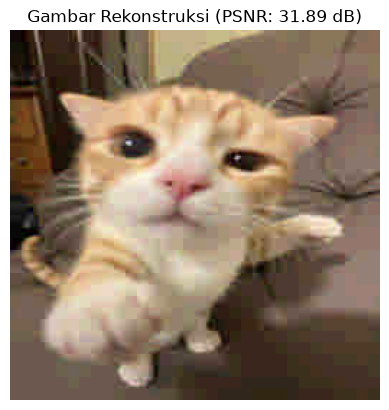

In [8]:
#hasil rekonstruksi (hasil compressed lossy)
plt.imshow(reconstructed_img)
plt.title(f"Gambar Rekonstruksi (PSNR: {psnr_value:.2f} dB)")
plt.axis('off')
plt.show()

In [9]:
#soal 4
#konversi gambar ke bitstream
def image_to_bitstream(img_array):
    return ''.join(format(byte, '08b') for byte in img_array.tobytes())
#fungsi bitstream gambar
def bitstream_to_image(bitstream, shape, dtype):
    byte_array = bytearray(int(bitstream[i:i+8], 2) for i in range(0, len(bitstream), 8))
    return np.frombuffer(byte_array, dtype=dtype).reshape(shape)

In [10]:
#encode hamming
def add_hamming_code(bitstream):
    encoded = []
    for i in range(0, len(bitstream), 4):
        d = bitstream[i:i+4].ljust(4, '0')
        p1 = str(int(d[0]) ^ int(d[1]) ^ int(d[3]))
        p2 = str(int(d[0]) ^ int(d[2]) ^ int(d[3]))
        p3 = str(int(d[1]) ^ int(d[2]) ^ int(d[3]))
        encoded.append(p1 + p2 + d[0] + p3 + d[1] + d[2] + d[3])
    return ''.join(encoded)

In [11]:
#deteksi konversi error
def detect_and_correct_hamming(encoded):
    corrected = []
    errors = []
    for i in range(0, len(encoded), 7):
        block = encoded[i:i+7]
        if len(block) < 7:
            corrected.append(block)
            continue
        p1, p2, d1, p3, d2, d3, d4 = block
        s1 = str(int(p1)^int(d1)^int(d2)^int(d4))
        s2 = str(int(p2)^int(d1)^int(d3)^int(d4))
        s3 = str(int(p3)^int(d2)^int(d3)^int(d4))
        # Hamming(7,4): parity is at positions 1, 2, 4, so the check covering position 1
        # is the LEAST significant syndrome bit. Order is s3 s2 s1, not s1 s2 s3.
        syndrome = s3 + s2 + s1
        pos = int(syndrome, 2) - 1
        if pos >= 0 and pos < 7:
            block = list(block)
            block[pos] = '0' if block[pos] == '1' else '1'
            errors.append(i + pos)
        corrected.append(''.join(block))
    return ''.join(corrected), errors

In [12]:
#hapus parity
def remove_hamming_code(encoded):
    return ''.join(encoded[i+2] + encoded[i+4] + encoded[i+5] + encoded[i+6] for i in range(0, len(encoded), 7))


In [13]:
#noise acak
def introduce_errors(bitstream, prob=0.005):
    bitstream = list(bitstream)
    error_locs = []
    for i in range(len(bitstream)):
        if np.random.rand() < prob:
            bitstream[i] = '1' if bitstream[i] == '0' else '0'
            error_locs.append(i)
    return ''.join(bitstream), error_locs

In [14]:
#pipeline channel coding
bitstream = image_to_bitstream(compressed_img)
encoded = add_hamming_code(bitstream)
corrupted, error_introduced = introduce_errors(encoded, prob=0.005)
corrected, error_detected = detect_and_correct_hamming(corrupted)
decoded = remove_hamming_code(corrected)
recovered_img = bitstream_to_image(decoded, compressed_img.shape, compressed_img.dtype)
#PSNR setelah error correction
psnr_recovered = calculate_psnr(img_np, recovered_img)

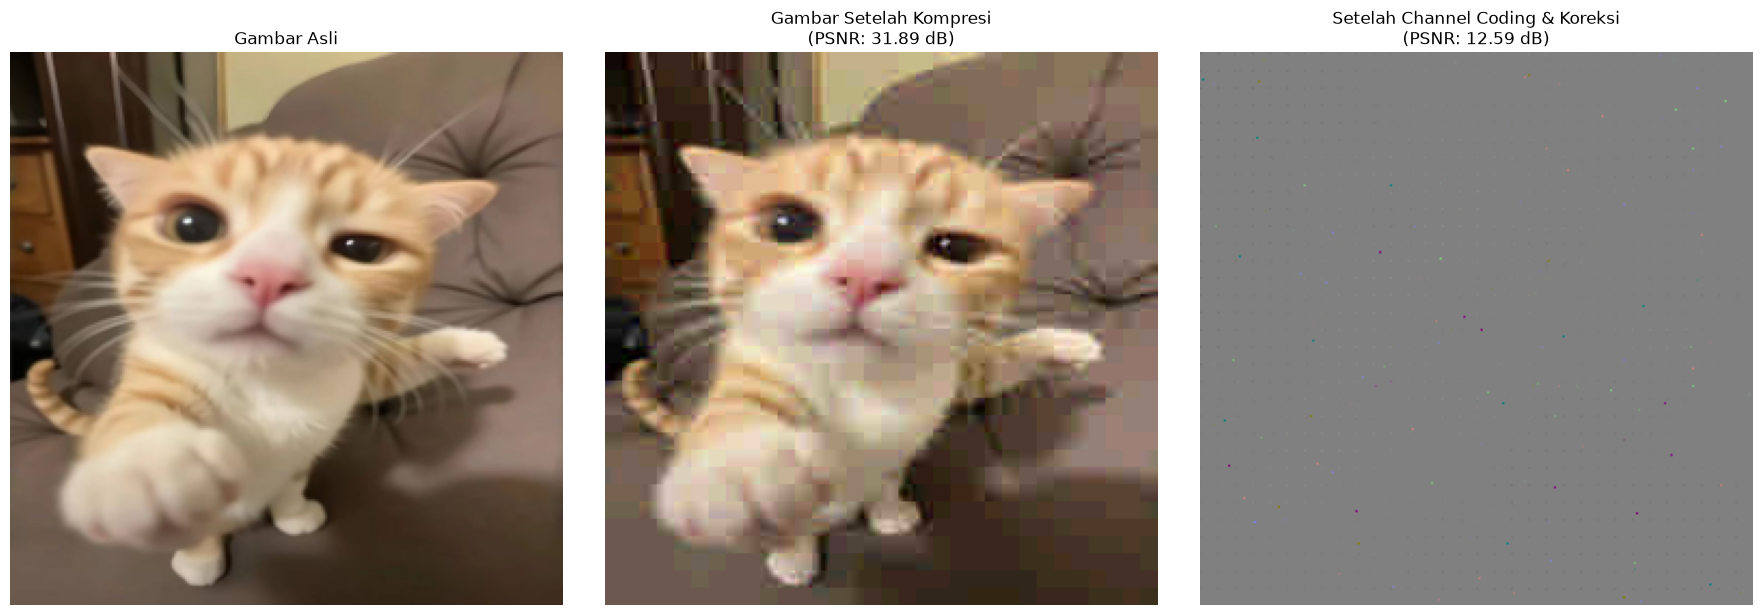

In [15]:
#hasi perbandingan
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
#gambar asli
axs[0].imshow(img_resized)
axs[0].set_title("Gambar Asli")
axs[0].axis('off')
#gambar setelah kompresi (DCT + Quantisasi)
axs[1].imshow(reconstructed_img)
axs[1].set_title(f"Gambar Setelah Kompresi\n(PSNR: {psnr_value:.2f} dB)")
axs[1].axis('off')
#gambar setelah channel coding dan koreksi error
axs[2].imshow(recovered_img)
axs[2].set_title(f"Setelah Channel Coding & Koreksi\n(PSNR: {psnr_recovered:.2f} dB)")
axs[2].axis('off')
plt.tight_layout()
plt.show()

In [16]:
#evaluasi
print("Evaluasi:")
print(f"- Jumlah bit error disisipkan   : {len(error_introduced)}")
print(f"- Jumlah bit error terdeteksi   : {len(error_detected)}")
print(f"- PSNR hasil setelah koreksi    : {psnr_recovered:.2f} dB")

Evaluasi:
- Jumlah bit error disisipkan   : 13950
- Jumlah bit error terdeteksi   : 13741
- PSNR hasil setelah koreksi    : 12.59 dB
